In [4]:
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

base_path = Path('cirrhosis.csv')

# Analiza i przetwarzanie danych pacjentów z marskością wątroby

#### Ten notebook ma na celu przeanalizowanie i przetworzenie zbioru danych pacjentów z marskością wątroby w taki sposób, by mógł on być użyty do nauki modelu klasyfikacji przeżywalności pacjenta (Status: D = zgon, C = cenzurowanie, CL = transplantacja wątroby).

Tabela z wyjaśnieniem poszczególnych kolumn:

| Kolumna           | Opis                                                                                          |
| ----------------- | --------------------------------------------------------------------------------------------- |
| **ID**            | Identyfikator pacjenta.                                                                       |
| **N_Days**        | Liczba dni obserwacji od rejestracji do śmierci, transplantacji watroby lub czasu badania w lipcu 1986r.                          |
| **Status**        | Status pacjenta (D = zgon, C = cenzurowanie, CL = transplantacja wątroby).                   |
| **Drug**          | Podawany lek (D-penicillamine lub Placebo).            |
| **Age**           | Wiek pacjenta w dniach.                                                                       |
| **Sex**           | Płeć pacjenta (F = kobieta, M = mężczyzna).                                                  |
| **Ascites**       | Obecność wodobrzusza (Y = tak, N = nie).                                                      |
| **Hepatomegaly**  | Powiększenie wątroby (Y = tak, N = nie).                                                      |
| **Spiders**       | Naczyniak pajączkowaty (Y = tak, N = nie).                                                    |
| **Edema**         | Obrzęk (N = brak, S = obrzęk bez terapii diuretycznej, Y = obrzęk mimo terapii).             |
| **Bilirubin**     | Stężenie bilirubiny w surowicy [mg/dl].                                                       |
| **Cholesterol**   | Stężenie cholesterolu w surowicy [mg/dl].                                                     |
| **Albumin**       | Stężenie albuminy w surowicy [mg/dl].                                                         |
| **Copper**        | Stężenie miedzi w moczu [ug/day].                                                             |
| **Alk_Phos**      | Aktywność fosfatazy alkalicznej [U/liter].                                                    |
| **SGOT**          | Aktywność aminotransferazy asparaginianowej [U/ml].                                           |
| **Tryglicerides** | Stężenie trójglicerydów w surowicy [mg/dl].                                                   |
| **Platelets**     | Liczba płytek krwi [ml/1000].                                                                 |
| **Prothrombin**   | Czas protrombinowy [s].                                                                       |
| **Stage**         | Stadium histologiczne marskości (1–4).                                                        |

## ***Podstawowa analiza i statystyka danych***

### Wczytanie danych

In [5]:
cirrhosis_data = pd.read_csv(base_path)

### Rozmiar danych

In [6]:
cirrhosis_data.shape

(418, 20)

Zbiór zawiera 418 rekordów zawierających dane pacjentów oraz 20 kolumn.

### Podgląd na parę pierwszych wartości

In [7]:
cirrhosis_data.head()

,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


### Opis danych

In [8]:
cirrhosis_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             418 non-null    int64  
 1   N_Days         418 non-null    int64  
 2   Status         418 non-null    str    
 3   Drug           312 non-null    str    
 4   Age            418 non-null    int64  
 5   Sex            418 non-null    str    
 6   Ascites        312 non-null    str    
 7   Hepatomegaly   312 non-null    str    
 8   Spiders        312 non-null    str    
 9   Edema          418 non-null    str    
 10  Bilirubin      418 non-null    float64
 11  Cholesterol    284 non-null    float64
 12  Albumin        418 non-null    float64
 13  Copper         310 non-null    float64
 14  Alk_Phos       312 non-null    float64
 15  SGOT           312 non-null    float64
 16  Tryglicerides  282 non-null    float64
 17  Platelets      407 non-null    float64
 18  Prothrombin    416 no

Mamy 12 kolumn numerycznych oraz 7 kolumn kategorialnych.  
Widzimy, że w kolumnach Drug, Ascites, Hepatomegaly, Spiders, Cholesterol, Copper, Alk_Phos, SGOT, Tryglicerides wystepuję znacząca ilość wartości null. W kolumnach Platelets, Prothombin oraz Stage występuje niewielka ilość wartości null.

### Sprawdzenie procentu brakujących wartości per kolumna

In [9]:
def get_percentage_missing(df, axis):
    missing = df.isna().sum(axis=axis)
    missing_perc = np.round(missing / df.shape[axis] * 100, 2)
    return missing_perc[missing_perc > 0]

missing_cols = get_percentage_missing(cirrhosis_data, axis=0)
print("Kolumny z brakującymi wartościami [%]:")
missing_cols

Kolumny z brakującymi wartościami [%]:


Drug             25.36
Ascites          25.36
Hepatomegaly     25.36
Spiders          25.36
Cholesterol      32.06
Copper           25.84
Alk_Phos         25.36
SGOT             25.36
Tryglicerides    32.54
Platelets         2.63
Prothrombin       0.48
Stage             1.44
dtype: float64

Jak widać sporo kolumn ma ponad 25% brakujących wartości, może tą wpłynąć na skuteczność uczenia modelu, ponieważ będzię on miał zbyt mało informacji/ zbyt mało wartości, żeby poprawnie nauczyć się klasyfikować. W miarę możlwiości w kolejnej sekcji tego notebooka zostanie przeprowadzone uzupełnienie danych null.

### Usunięcie kolumny ID, która nie ma żadnej wartości analitycznej

In [10]:
cirrhosis_data = cirrhosis_data.drop(columns=['ID'])
cirrhosis_data.head(1)

,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.6,156.0,1718.0,137.95,172.0,190.0,12.2,4.0


### Podstawowe statystyki dla kolumn numerycznych

In [11]:
cirrhosis_data.describe()

,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
count,418.000000,418.000000,418.000000,284.000000,418.000000,310.000000,312.000000,312.000000,282.000000,407.000000,416.000000,412.000000
mean,1917.782297,18533.351675,3.220813,369.510563,3.497440,97.648387,1982.655769,122.556346,124.702128,257.024570,10.731731,3.024272
std,1104.672992,3815.845055,4.407506,231.944545,0.424972,85.613920,2140.388824,56.699525,65.148639,98.325585,1.022000,0.882042
min,41.000000,9598.000000,0.300000,120.000000,1.960000,4.000000,289.000000,26.350000,33.000000,62.000000,9.000000,1.000000
25%,1092.750000,15644.500000,0.800000,249.500000,3.242500,41.250000,871.500000,80.600000,84.250000,188.500000,10.000000,2.000000
50%,1730.000000,18628.000000,1.400000,309.500000,3.530000,73.000000,1259.000000,114.700000,108.000000,251.000000,10.600000,3.000000
75%,2613.500000,21272.500000,3.400000,400.000000,3.770000,123.000000,1980.000000,151.900000,151.000000,318.000000,11.100000,4.000000
max,4795.000000,28650.000000,28.000000,1775.000000,4.640000,588.000000,13862.400000,457.250000,598.000000,721.000000,18.000000,4.000000


### Sprawdzenie czy jakiś wiersz zawiera znaczącą liczbę wartości NaN

In [12]:
missing_rows_sorted = get_percentage_missing(cirrhosis_data, axis=1).sort_values(ascending=False)
print("Wiersze z brakującymi wartościami posortowane malejąco [%]:")
print(missing_rows_sorted)
print()
rows_to_drop = missing_rows_sorted[missing_rows_sorted >= 50].index
print("Numery wierszy do usunięcia (>= 50% brakujących wartości):", rows_to_drop.tolist())

Wiersze z brakującymi wartościami posortowane malejąco [%]:
358    52.63
333    52.63
332    52.63
336    52.63
346    52.63
       ...  
125     5.26
237     5.26
260     5.26
128     5.26
167     5.26
Length: 142, dtype: float64

Numery wierszy do usunięcia (>= 50% brakujących wartości): [358, 333, 332, 336, 346, 342, 324, 326, 327, 312, 318, 321, 316, 315, 367]


Mamy  15 wierszy, które zawierają mniej niż 50 % danych o pacjencie.
Jako iż jest to znaczący procent, te wiersze zostaną usunięte. 

In [13]:
cirrhosis_data = cirrhosis_data.drop(index=rows_to_drop)
print("Rozmiar po usunięciu wierszy:", cirrhosis_data.shape)

Rozmiar po usunięciu wierszy: (403, 19)


Po tym działaniu liczba wartości NULL w poszczególnych kolumnach prezętuję się następująco:

In [14]:
cirrhosis_data.info()

<class 'pandas.DataFrame'>
Index: 403 entries, 0 to 417
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   N_Days         403 non-null    int64  
 1   Status         403 non-null    str    
 2   Drug           312 non-null    str    
 3   Age            403 non-null    int64  
 4   Sex            403 non-null    str    
 5   Ascites        312 non-null    str    
 6   Hepatomegaly   312 non-null    str    
 7   Spiders        312 non-null    str    
 8   Edema          403 non-null    str    
 9   Bilirubin      403 non-null    float64
 10  Cholesterol    284 non-null    float64
 11  Albumin        403 non-null    float64
 12  Copper         310 non-null    float64
 13  Alk_Phos       312 non-null    float64
 14  SGOT           312 non-null    float64
 15  Tryglicerides  282 non-null    float64
 16  Platelets      399 non-null    float64
 17  Prothrombin    403 non-null    float64
 18  Stage          403 non-nul

# **Pozbycie się brakujących wartości**

Brakujące wartości:
- **Drug** (brakuje 91) – kolumna kategorialna
- **Ascites** (brakuje 91) – kolumna kategorialna
- **Hepatomegaly** (brakuje 91) – kolumna kategorialna
- **Spiders** (brakuje 91) – kolumna kategorialna
- **Cholesterol** (brakuje 119) – kolumna numeryczna
- **Copper** (brakuje 93) – kolumna numeryczna
- **Alk_Phos** (brakuje 91) – kolumna numeryczna
- **SGOT** (brakuje 91) – kolumna numeryczna
- **Tryglicerides** (brakuje 121) – kolumna numeryczna
- **Platelets** (brakuje 4) – kolumna numeryczna

## Kolumny numeryczne

Definiuję funkcję pomocniczą do rysowania histogramu z zaznaczoną średnią i medianą aby podjąć decyzję czym uzupełniać brakujące dane.

In [15]:
def plot_numeric_histogram(df, column_name):
    data = df[column_name].dropna()
    mean_val = data.mean()
    median_val = data.median()

    plt.figure(figsize=(6, 4))
    plt.hist(data, bins=30, color='steelblue', edgecolor='black')
    plt.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_val:.2f}')
    plt.axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Median: {median_val:.2f}')

    plt.title(f'Distribution of {column_name}')
    plt.xlabel(column_name)
    plt.ylabel('Frequency')
    plt.legend()
    plt.tight_layout()
    plt.show()

### Cholesterol

Dla zmiennej Cholesterol najpierw zbadam jej rozkład, aby sprawdzić czy sensowniejsze jest uzupełnienie brakujących wartości średnią czy też medianą

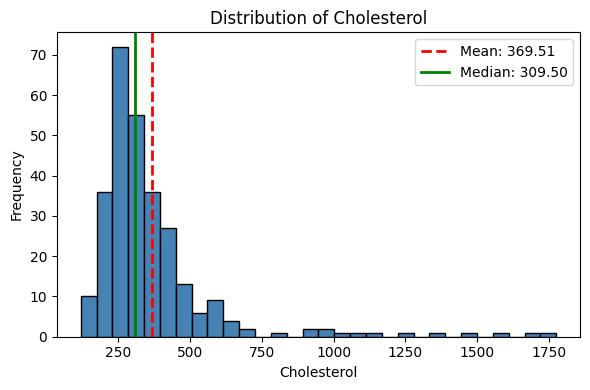

In [16]:
plot_numeric_histogram(cirrhosis_data, 'Cholesterol')

Można założyć, że jest to rozkład asymetryczny prawoskośny, ponieważ:
* większość wartości skupia się po lewej stronie (około 200–400),
* po prawej stronie jest długi „ogon” aż do bardzo dużych wartości (~1800),
* średnia jest większa od mediany(ponieważ kilka bardzo dużych wartości cholesterolu ciągnie średnią w prawo)

Zatem brakujące wartości w kolumnie Cholesterol uzupełnię medianą. Przy skośnym/ asymetrycznym rozkładzie danych jest to bezpieczniejsze, użycie średniej mogłoby zawyżyć wiele brakujących wartości.


In [17]:
cirrhosis_data['Cholesterol'] = cirrhosis_data['Cholesterol'].fillna(cirrhosis_data['Cholesterol'].median())
cirrhosis_data['Cholesterol'].isna().sum()

np.int64(0)

### Copper

Dla zmiennej Copper również zbadam jej rozkład przed uzupełnieniem braków

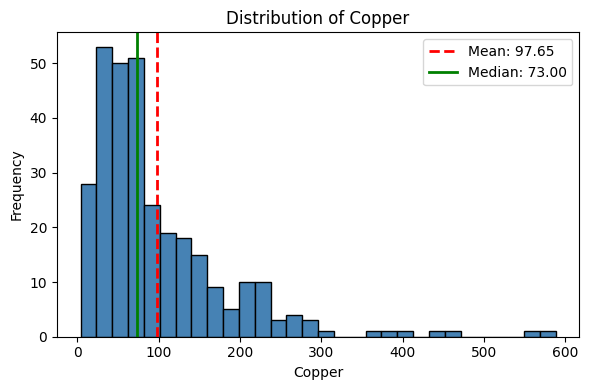

In [18]:
plot_numeric_histogram(cirrhosis_data, 'Copper')

Ponownie dane mają rozkład asymetryczny prawoskośny, dlatego ponownie brakujące wartości wypełnią medianą.

In [19]:
cirrhosis_data['Copper'] = cirrhosis_data['Copper'].fillna(cirrhosis_data['Copper'].median())
cirrhosis_data['Copper'].isna().sum()

np.int64(0)

### Alk_Phos

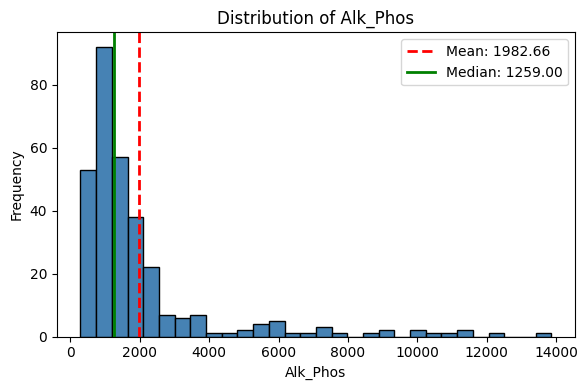

In [20]:
plot_numeric_histogram(cirrhosis_data, 'Alk_Phos')

Również można założyć, że mamy tutaj do czynienia z rozkładem asymetrycznie prawoskośnym, więc dane ponownie uzupełnie medianą.

In [21]:
cirrhosis_data['Alk_Phos'] = cirrhosis_data['Alk_Phos'].fillna(cirrhosis_data['Alk_Phos'].median())
cirrhosis_data['Alk_Phos'].isna().sum()

np.int64(0)

### SGOT

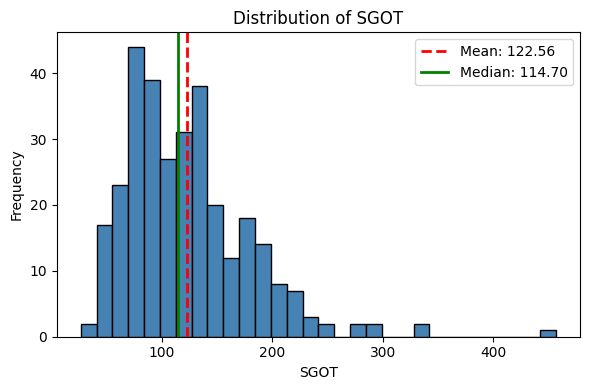

In [22]:
plot_numeric_histogram(cirrhosis_data, 'SGOT')

Rozkład dla cechy SGOT jest już bliski rozkładowi normalnemu, jednak wciąż jest lekko prawoskośny. Różnica między medianą oraz średnią jest niewielka, dlatego w tym przypadku zdecydowałam się zastapić wartości NULL średnią.

In [23]:
cirrhosis_data['SGOT'] = cirrhosis_data['SGOT'].fillna(cirrhosis_data['SGOT'].mean())
cirrhosis_data['SGOT'].isna().sum()

np.int64(0)

### Tryglicerides

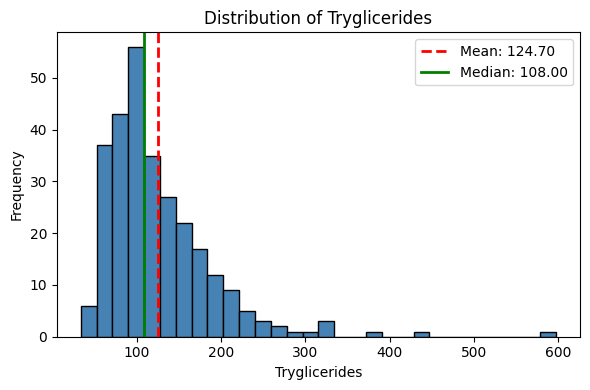

In [24]:
plot_numeric_histogram(cirrhosis_data, 'Tryglicerides')

Ponownie dane mają rozkład asymetryczny prawoskośny, dlatego ponownie brakujące wartości wypełnią medianą.

In [25]:
cirrhosis_data['Tryglicerides'] = cirrhosis_data['Tryglicerides'].fillna(cirrhosis_data['Tryglicerides'].median())
cirrhosis_data['Tryglicerides'].isna().sum()

np.int64(0)

### Platelets

W kolumnie Platelets brakuje tylko 4 wartości. Sprawdzę rozkład i uzupełnię medianą lub średnią.

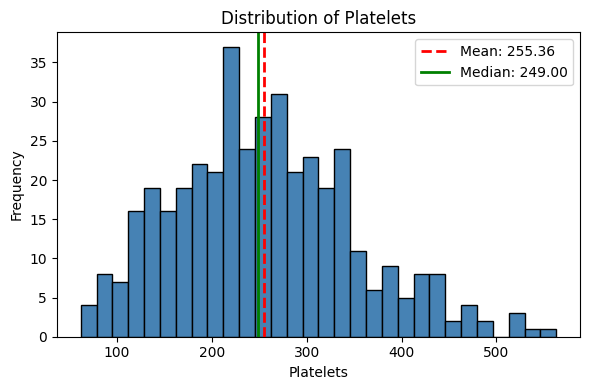

In [26]:
plot_numeric_histogram(cirrhosis_data, 'Platelets')

Rozkład dla cechy Plateles jest można uznać za rozkład normalny. Różnica między medianą oraz średnią jest minimalna. W tym przypadku najlepszym rowiązaniem jest uzupełnienie wartości NULL średnią.

In [27]:
cirrhosis_data['Platelets'] = cirrhosis_data['Platelets'].fillna(cirrhosis_data['Platelets'].mean())
cirrhosis_data['Platelets'].isna().sum()

np.int64(0)

## Kolumny kategorialne

Definiuję funkcję pomocniczą do pobierania rozkładu wartości kolumny

In [28]:
def get_column_distribution(df, column):
    return df[column].value_counts(normalize=True)

### Drug

Kolumna Drug jest kategorialna z 2 możliwymi wartościami. Sprawdzę rozkład danych.

In [29]:
cirrhosis_data['Drug'].isna().sum()

np.int64(91)

In [30]:
cirrhosis_data['Drug'].unique()

<StringArray>
['D-penicillamine', 'Placebo', nan]
Length: 3, dtype: str

In [31]:
drug_dist = get_column_distribution(cirrhosis_data, 'Drug')
drug_dist

Drug
D-penicillamine    0.50641
Placebo            0.49359
Name: proportion, dtype: float64

Rozkład wartości Drug jest zbliżony (około 50% wierszy ma wartość D-penicillamine i około 50% wierszy ma wartość Placebo). Brakujące wartości można uzupełnić:
1) wartością najczęścięj występującą w kolumnie (tutaj bez sensu)
2) zgodnie z rozkładem istniejących danych, losowo uzupełniająć wartości brakujące
3) dodając nową wartość Drug = "Unknown" dla wierszy z NULLami

Jako iż mamy 91 brakujących wartości losowe uzupełnienie według rozkładu danych mogłoby wpłynąć na skuteczność modelu, dlatego zdecydowałam się użyć podejścia nr 3. 

In [32]:
cirrhosis_data['Drug'] = cirrhosis_data['Drug'].fillna("Unknown")

In [33]:
cirrhosis_data['Drug'].isna().sum()

np.int64(0)

In [34]:
cirrhosis_data['Drug'].unique()

<StringArray>
['D-penicillamine', 'Placebo', 'Unknown']
Length: 3, dtype: str

### Ascites

Kolumna Ascites jest binarna (Y/N). Sprawdzę rozkład danych.

In [35]:
ascites_dist = get_column_distribution(cirrhosis_data, 'Ascites')
ascites_dist

Ascites
N    0.923077
Y    0.076923
Name: proportion, dtype: float64

Brakujące dane zdecydowałam się uzupełnić losowo według rozkładu danych. Mimo, że większośc danych w kolumnie Ascites ma wartość 'N', to uzupełnienie wszystkich 91 wierszy z wartością NaN za pomocą 'N' mogłoby negatywnie wpłynąć na skuteczność modelu.

In [36]:
ascites_dist = get_column_distribution(cirrhosis_data, 'Ascites')
ascites_values = ascites_dist.index
ascites_probs = ascites_dist.values
missing_ascites = cirrhosis_data['Ascites'].isna()
cirrhosis_data.loc[missing_ascites, 'Ascites'] = np.random.choice(ascites_values, size=missing_ascites.sum(), p=ascites_probs)
cirrhosis_data['Ascites'].isna().sum()

np.int64(0)

### Hepatomegaly

Kolumna Hepatomegaly jest binarna (Y/N). Sprawdzę rozkład danych.

In [37]:
cirrhosis_data['Hepatomegaly'].value_counts()

Hepatomegaly
Y    160
N    152
Name: count, dtype: int64

Tutaj tak jak w przypadku kolumny Drug mamy prawie rozkład 50/50 pomiędzy wartościami 'Y' oraz 'N'. DLatego zdecydowałam się dodać wartość "Unknown" i nią uzupełnić wartości brakujące.

In [38]:
cirrhosis_data['Hepatomegaly'] = cirrhosis_data['Hepatomegaly'].fillna("Unknown")
cirrhosis_data['Hepatomegaly'].isna().sum()

np.int64(0)

In [39]:
cirrhosis_data['Hepatomegaly'].unique()

<StringArray>
['Y', 'N', 'Unknown']
Length: 3, dtype: str

### Spiders

Kolumna Spiders jest binarna (Y/N). Sprawdzę rozkład danych.

In [40]:
cirrhosis_data['Spiders'].value_counts()

Spiders
N    222
Y     90
Name: count, dtype: int64

Brakujące dane zdecydowałam się uzupełnić losowo według rozkładu danych. 

In [41]:
spiders_dist = get_column_distribution(cirrhosis_data, 'Spiders')
spiders_values = spiders_dist.index
spiders_probs = spiders_dist.values
missing_spiders = cirrhosis_data['Spiders'].isna()
cirrhosis_data.loc[missing_spiders, 'Spiders'] = np.random.choice(spiders_values, size=missing_spiders.sum(), p=spiders_probs)
cirrhosis_data['Spiders'].isna().sum()

np.int64(0)

## Weryfikacja – brak wartości NaN

In [42]:
cirrhosis_data.isna().sum()

N_Days           0
Status           0
Drug             0
Age              0
Sex              0
Ascites          0
Hepatomegaly     0
Spiders          0
Edema            0
Bilirubin        0
Cholesterol      0
Albumin          0
Copper           0
Alk_Phos         0
SGOT             0
Tryglicerides    0
Platelets        0
Prothrombin      0
Stage            0
dtype: int64

# **Wykrywanie outlierów**

Definiuję funkcję pomocniczą do rysowania wykresu pudełkowego (boxplot)

In [43]:
def boxplot(df, column_name):
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[column_name].dropna(), color='lightgreen')
    plt.title(f'Distribution of {column_name} (boxplot)')
    plt.xlabel(column_name)
    plt.show()

Definiuję funkcję pomocniczą do rysowania scatter plot

In [44]:
def scatterplot(df, column_name, y):
    plt.figure(figsize=(6, 4))
    sns.scatterplot(data=df, x=column_name, y=y, color='darkorange', alpha=0.6)
    plt.title(f'{column_name} vs {y}')
    plt.xlabel(column_name)
    plt.ylabel(y)
    plt.tight_layout()
    plt.show()

### Bilirubin

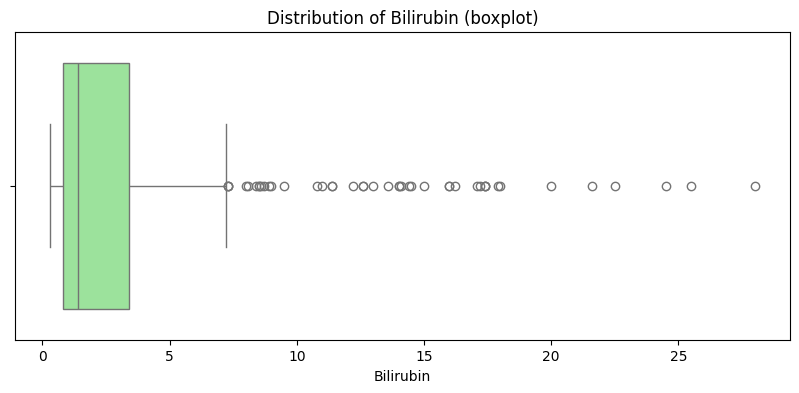

In [45]:
boxplot(cirrhosis_data, 'Bilirubin')

Można zauważyć, że w kolumnie Bilirubin jest sporo outlierów. Możemy albo usunąć wartości odstające albo pozostawić je, ponieważ mogą mieć duża wartość dla modelu, być mocno powiązane z wartością w kolumnie Status.

Dlatego sprawdzę czy nie ma korelacji pomiędzy wysokim Bilirubin, a statusem pacjenta.

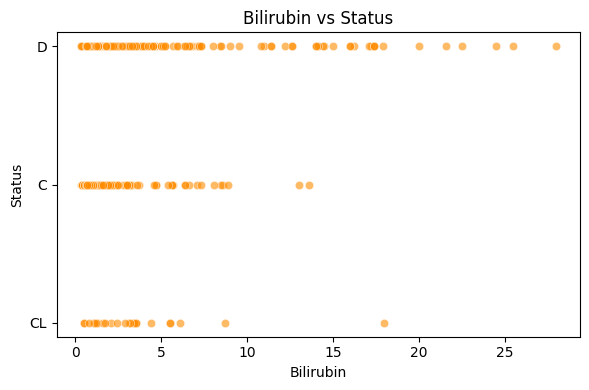

In [46]:
scatterplot(cirrhosis_data, 'Bilirubin', 'Status')

Jak widać dla wysokich wartości w kolumnie Bilirubin w większości status ma wartosć 'D'. Dlatego zdecydowałam się nie usuwać outlierów.

### Cholesterol

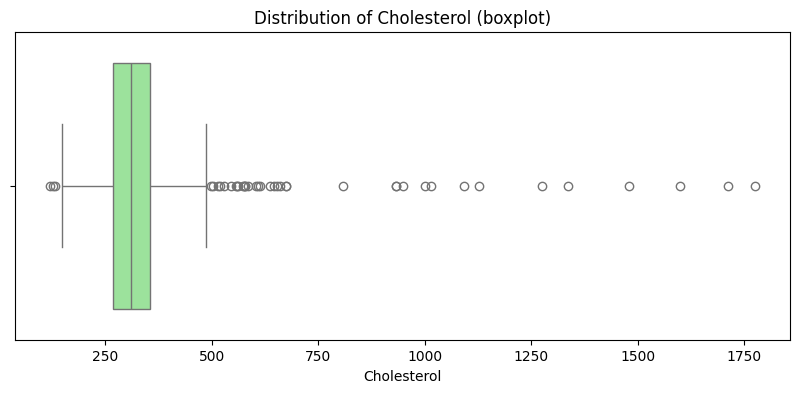

In [47]:
boxplot(cirrhosis_data, 'Cholesterol')

Dla kolumny Cholesterol również występuję wiele wartości odstających.
Również sprawdzę czy nie ma korelacji pomiędzy wysokim Cholesterolem, a statusem pacjenta.

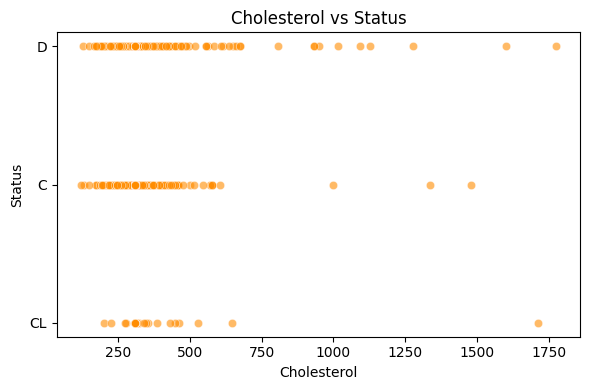

In [48]:
scatterplot(cirrhosis_data, 'Cholesterol', 'Status')

Dla odstających wartości w kolumnie Cholesterol , Status ma zarówno wartość 'D', 'C', 'CL', z dominującą wartością 'D', dlatego mimo wszytsko zdecydowałam się pozostawić te outliery.

### Copper

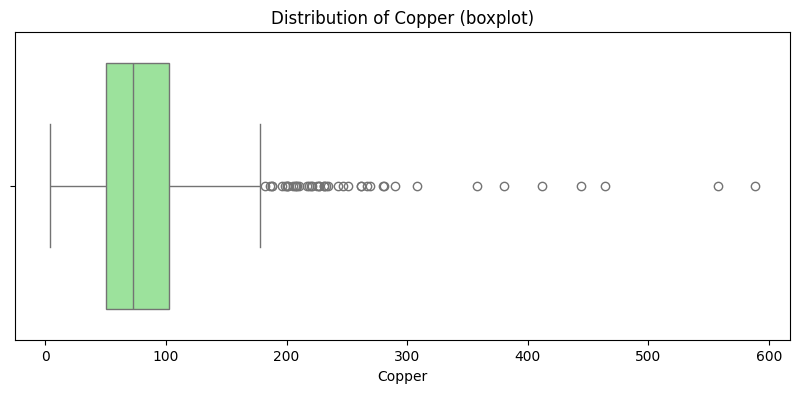

In [49]:
boxplot(cirrhosis_data, 'Copper')

Sprawdzę czy wysokie wartości Copper korelują z długością przeżycia pacjenta

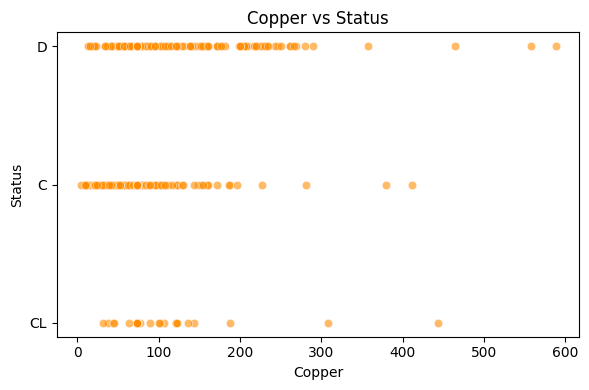

In [50]:
scatterplot(cirrhosis_data, 'Copper', 'Status')

Dla odstających wartości w kolumnie Copper , Status ma zarówno wartość 'D', 'C', 'CL'. Zdecydowałam się pozostawić te outliery.

### Alk_Phos

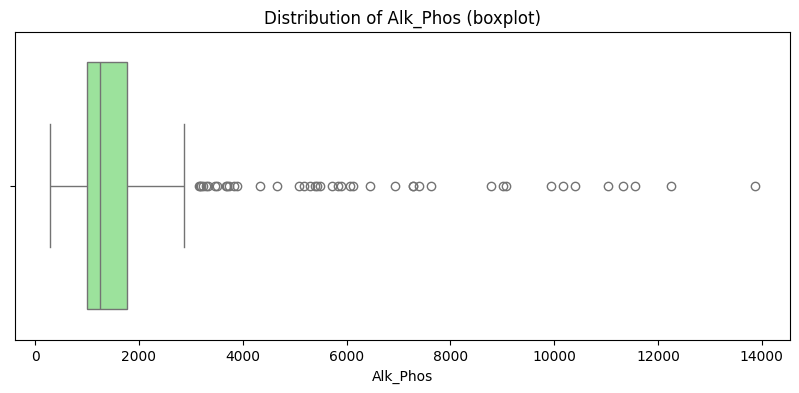

In [51]:
boxplot(cirrhosis_data, 'Alk_Phos')

Sprawdzę czy wysokie wartości Alk_Phos korelują z długością przeżycia pacjenta

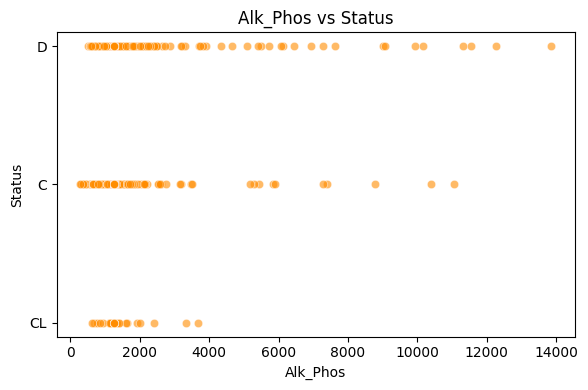

In [52]:
scatterplot(cirrhosis_data, 'Alk_Phos', 'Status')

Dla odstających wartości w kolumnie Alk_Phos , Status ma zarówno wartość 'D', 'C', 'CL'. Zdecydowałam się pozostawić te outliery.

### SGOT

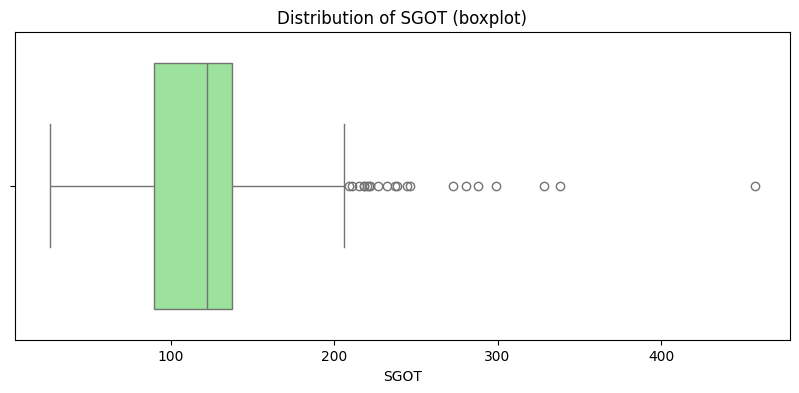

In [53]:
boxplot(cirrhosis_data, 'SGOT')

Sprawdzę czy wysokie wartości SGOT nkorelują z długością przeżycia pacjenta

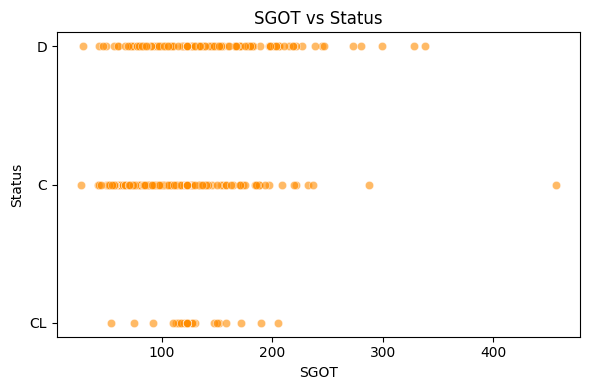

In [54]:
scatterplot(cirrhosis_data, 'SGOT', 'Status')

Dla odstających wartości w kolumnie SGOT , Status ma zarówno wartość 'D', 'C', 'CL'. Zdecydowałam się usunąć mocno odbiegająca wartość po prawej stronie. Usunę ją używając progu - 3*QR.

In [82]:
Q1 = cirrhosis_data['SGOT'].quantile(0.25)
Q3 = cirrhosis_data['SGOT'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 3.0 * IQR
upper_bound = Q3 + 3.0 * IQR

cirrhosis_data = cirrhosis_data[(cirrhosis_data['SGOT'] >= lower_bound) &
                                        (cirrhosis_data['SGOT'] <= upper_bound)]

### Tryglicerides

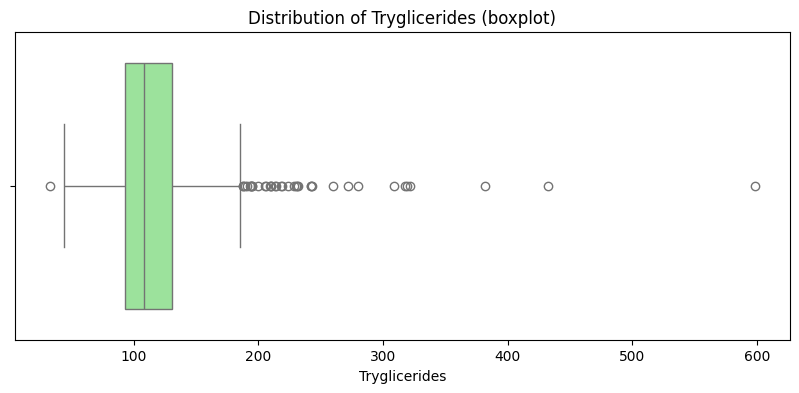

In [55]:
boxplot(cirrhosis_data, 'Tryglicerides')

Sprawdzę czy wysokie wartości Tryglicerides nkorelują z długością przeżycia pacjenta

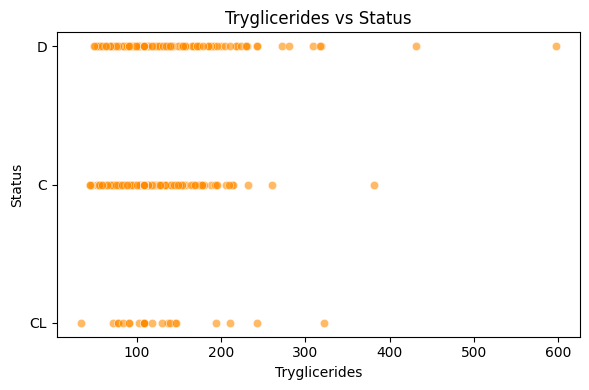

In [56]:
scatterplot(cirrhosis_data, 'Tryglicerides', 'Status')

### Platelets

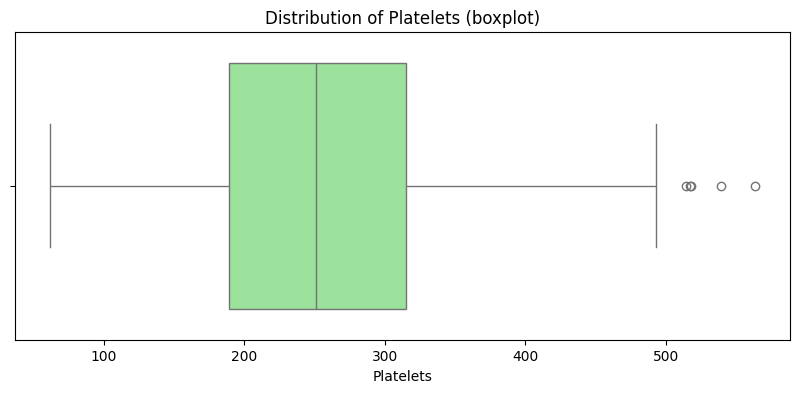

In [57]:
boxplot(cirrhosis_data, 'Platelets')

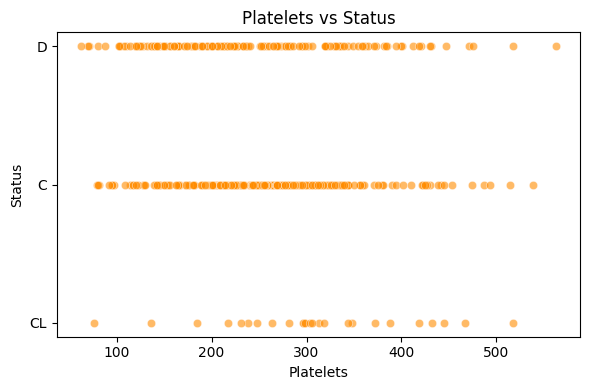

In [58]:
scatterplot(cirrhosis_data, 'Platelets', 'Status')

Dla odstających wartości w kolumnie Plateles , Status ma zarówno wartość 'D', 'C', 'CL'. Zdecydowałam się usunąć mocno odbiegającae wartość po prawej stronie. Usunę ją używając progu - 3*QR.

In [83]:
Q1 = cirrhosis_data['Platelets'].quantile(0.25)
Q3 = cirrhosis_data['Platelets'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 3.0 * IQR
upper_bound = Q3 + 3.0 * IQR

cirrhosis_data = cirrhosis_data[(cirrhosis_data['Platelets'] >= lower_bound) &
                                        (cirrhosis_data['Platelets'] <= upper_bound)]

### Prothrombin

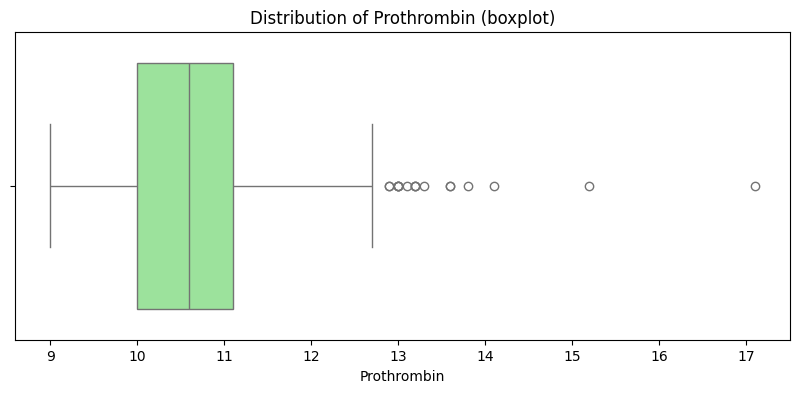

In [59]:
boxplot(cirrhosis_data, 'Prothrombin')

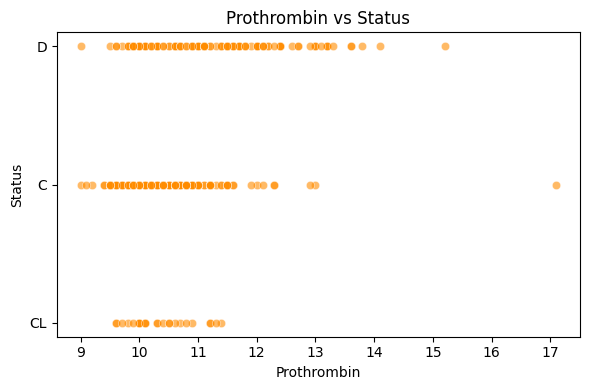

In [60]:
scatterplot(cirrhosis_data, 'Prothrombin', 'Status')

#### Dla kolumn kategorialnych binarnych (Drug, Ascites, Hepatomegaly, Spiders, Sex, Edema) oraz dla Stage nie ma potrzeby badania outlierów – każda z nich ma wartości z ściśle określonego, skończonego zbioru.

# **Wizualizacje danych**

Sprawdzę rozkład statusów pacjentów – zmiennej docelowej

C:\Users\mazur\AppData\Local\Temp\ipykernel_30012\803747020.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Status', data=cirrhosis_data, palette='viridis')


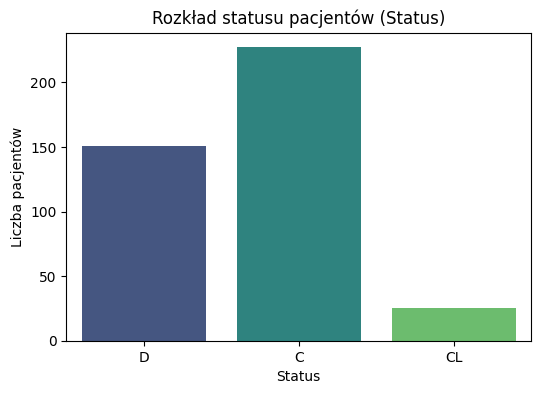

In [61]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Status', data=cirrhosis_data, palette='viridis')
plt.title('Rozkład statusu pacjentów (Status)')
plt.xlabel('Status')
plt.ylabel('Liczba pacjentów')
plt.show()

Mamy ponad 200 pacjentów ze statusem 'C' oraz 150 pacjentów ze statusem 'D'. Najrzadziej występującą wartościa jest 'CL'. Można się spodziewać, że klasyfikacja tego statusu może być najtrudniejsza.

Sprawdzę rozkład stadium choroby (Stage) w zależności od statusu pacjenta za pomocą heatmapy

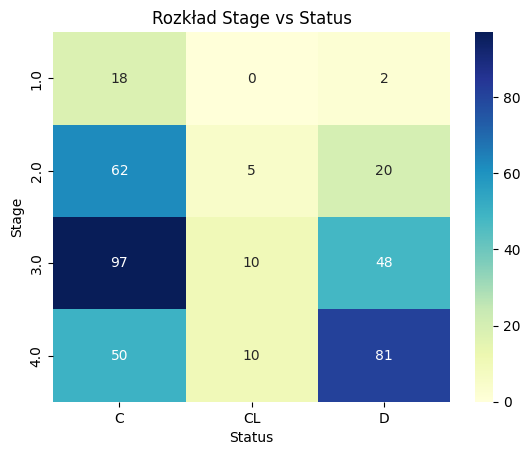

In [62]:
cross_tab = pd.crosstab(cirrhosis_data['Stage'], cirrhosis_data['Status'])
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Rozkład Stage vs Status')
plt.show()

Można uznać, że dla Stage 3.0 oraz 4,0 zarówno wartości 'C' oraz 'CL' jak i 'D' występują częsciej, co zonacza, że nie można uznać, że wysoki Stage przyczynia się do większej śmiertelności pacjenta. Może to również oznaczać, że po prostu większość badanych pacjentów miała Stahe 3/4.

Sprawdzę jak rozkłada się płeć wśród pacjentów.

C:\Users\mazur\AppData\Local\Temp\ipykernel_30012\663230330.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sex', data=cirrhosis_data, palette='viridis')


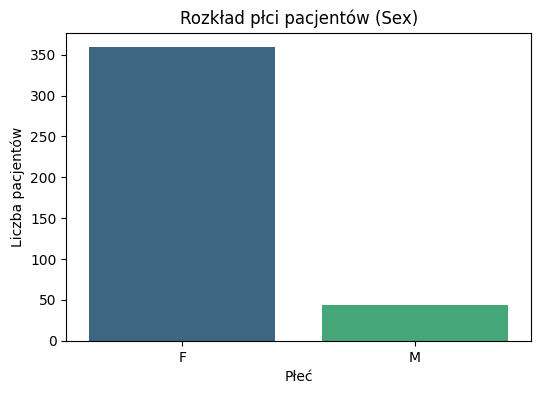

In [63]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Sex', data=cirrhosis_data, palette='viridis')
plt.title('Rozkład płci pacjentów (Sex)')
plt.xlabel('Płeć')
plt.ylabel('Liczba pacjentów')
plt.show()

Sprawdzę czy płeć pacjenta ma związek ze statusem (przeżywalnością)

C:\Users\mazur\AppData\Local\Temp\ipykernel_30012\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


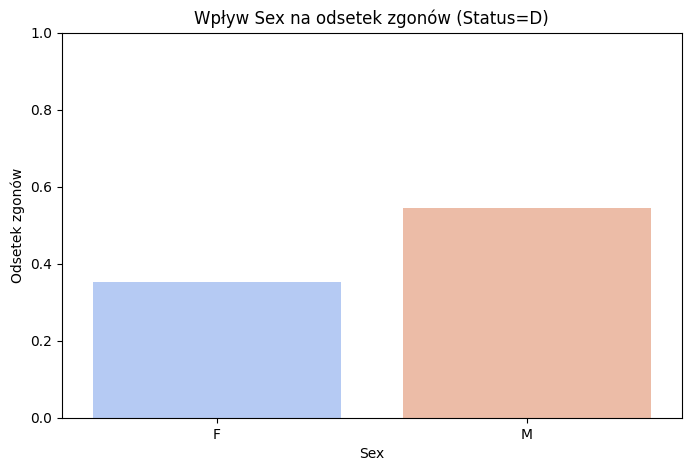

In [64]:
def plot_status_barplot(df, category_col):
    death_rate = df[df['Status'] == 'D'].groupby(category_col).size() / df.groupby(category_col).size()
    death_rate = death_rate.reset_index(name='Odsetek zgonów')

    plt.figure(figsize=(8, 5))
    sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')
    plt.title(f'Wpływ {category_col} na odsetek zgonów (Status=D)')
    plt.xlabel(category_col)
    plt.ylabel('Odsetek zgonów')
    plt.ylim(0, 1)
    plt.show()

plot_status_barplot(cirrhosis_data, 'Sex')

Większa śmiertelność występuję wśród mężczyzn, jednak większość pacjentek to kobiety, dlatego ciężko określić czy śmiertelność koreluje z płcią, czy tez dla kobiet odsetek zgonów jest niższy przez większą liczbę rekordów.

Sprawdzę wpływ obecności objawów klinicznych (Ascites, Hepatomegaly, Spiders, Edema) na odsetek zgonów

C:\Users\mazur\AppData\Local\Temp\ipykernel_30012\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


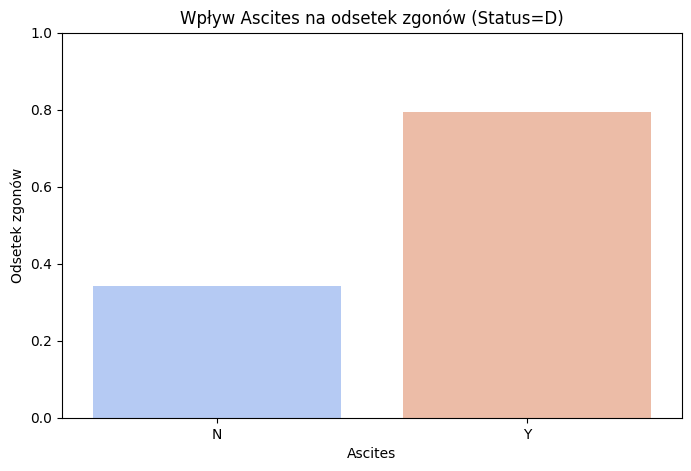

C:\Users\mazur\AppData\Local\Temp\ipykernel_30012\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


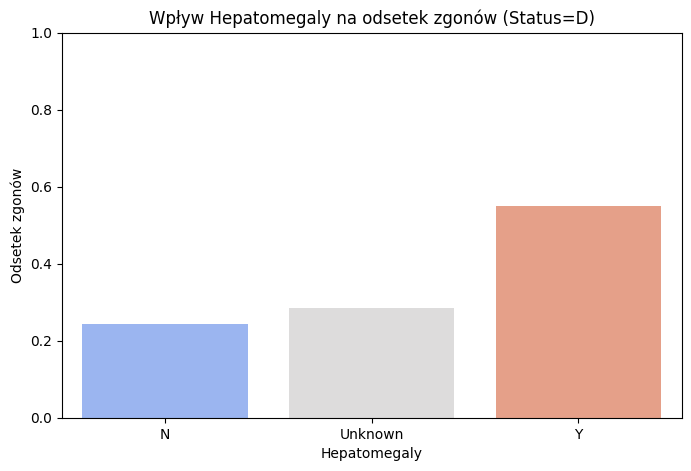

C:\Users\mazur\AppData\Local\Temp\ipykernel_30012\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


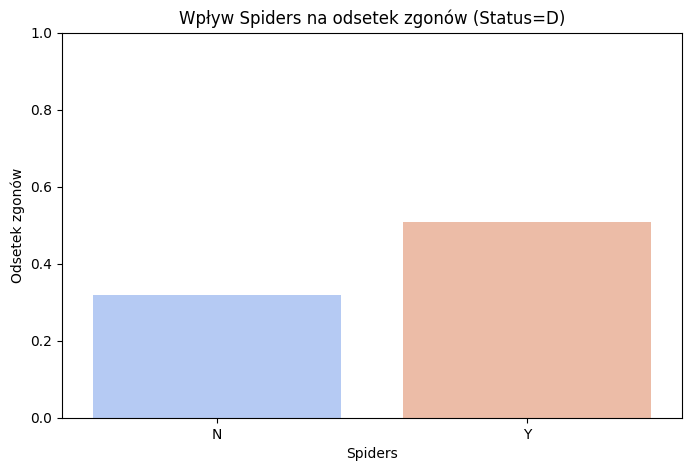

C:\Users\mazur\AppData\Local\Temp\ipykernel_30012\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


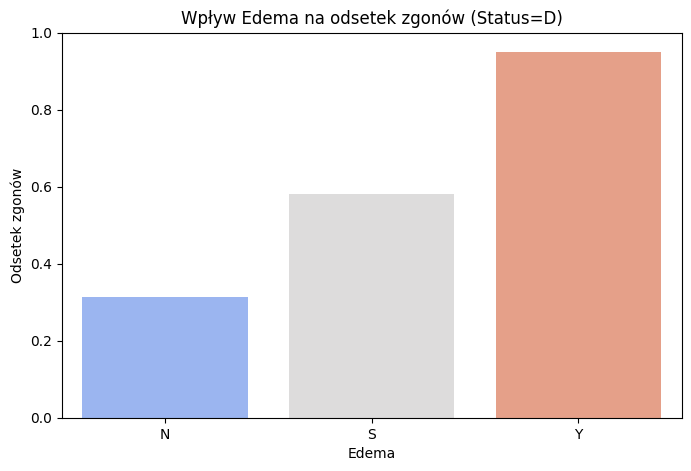

In [65]:
plot_status_barplot(cirrhosis_data, 'Ascites')
plot_status_barplot(cirrhosis_data, 'Hepatomegaly')
plot_status_barplot(cirrhosis_data, 'Spiders')
plot_status_barplot(cirrhosis_data, 'Edema')

Dla wszystkich 4 cech widzimy, że obecnośc objawów klinicznych koreluje z wyższym odsetkiem zgonów, więc mogą to być to kluczowe cechy dla modelu.

Sprawdzę czy podawany lek (Drug) miał wpływ na wynik leczenia

C:\Users\mazur\AppData\Local\Temp\ipykernel_30012\2559971816.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=category_col, y='Odsetek zgonów', data=death_rate, palette='coolwarm')


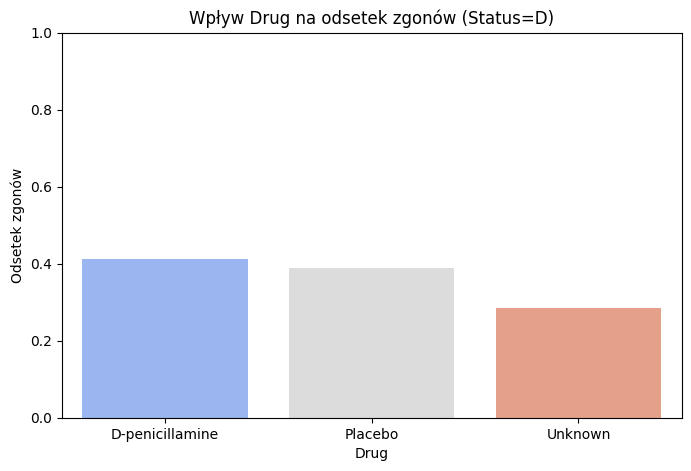

In [66]:
plot_status_barplot(cirrhosis_data, 'Drug')

Podawany lek nie wykazuje silnej zależności z Statusem pacjentów, dla wszystkich 3 wartości w kolumnie Drug odetek zgonów jest na podobnym poziomie, możemy zatem uznać, że nie będzie to kluczowa cecha dla naszego modelu.

Sprawdzę zależność Bilirubin i Albumin od stadium choroby za pomocą pivot table i heatmapy

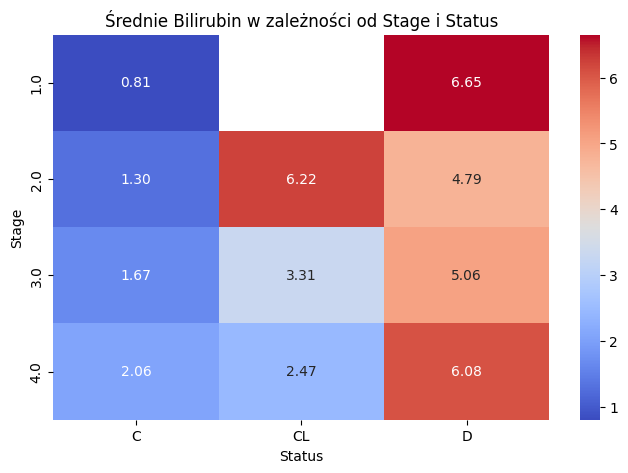

In [67]:
pivot_bilirubin = cirrhosis_data.pivot_table(index='Stage', columns='Status', values='Bilirubin', aggfunc='mean')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_bilirubin, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Średnie Bilirubin w zależności od Stage i Status')
plt.ylabel('Stage')
plt.xlabel('Status')
plt.show()

Widać, że dla Statusu 'D' średnie Bilirubin jest wyższe, więc może ono mieć wpływ na śmiertelność pacjenta.

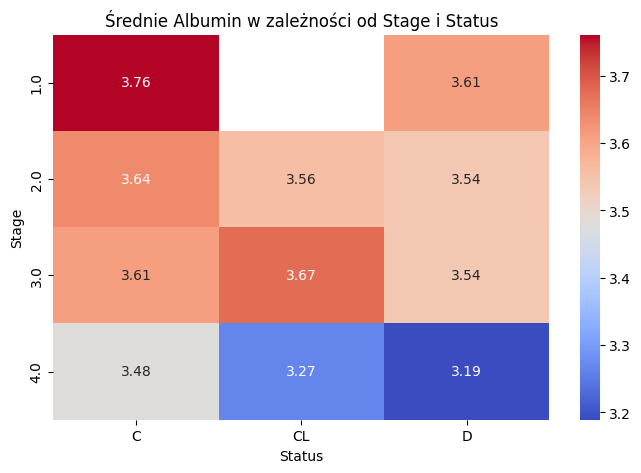

In [68]:
pivot_albumin = cirrhosis_data.pivot_table(index='Stage', columns='Status', values='Albumin', aggfunc='mean')

plt.figure(figsize=(8, 5))
sns.heatmap(pivot_albumin, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Średnie Albumin w zależności od Stage i Status')
plt.ylabel('Stage')
plt.xlabel('Status')
plt.show()

Nie widać większej zależności pomiędzy cechą Status i Stage, a średnią Albumin. Większość wartości na heatmapie są do siebie zbliżone.

# Zakodowanie wartości kategorialnych

Dla kolumn : Ascites oraz Spiders, które przyjmują jedną z wartości Y/N zastosuje kodowanie binarne.

In [69]:
cirrhosis_data.Ascites.unique()
cirrhosis_data.Spiders.unique()

<StringArray>
['Y', 'N']
Length: 2, dtype: str

In [70]:
cirrhosis_data['Ascites'] = cirrhosis_data.Ascites.map({
    'Y': 1, 'N': 0
})
cirrhosis_data['Spiders'] = cirrhosis_data.Spiders.map({
    'Y': 1, 'N': 0
})

In [71]:
cirrhosis_data.Ascites.unique()
cirrhosis_data.Spiders.unique()

array([1, 0])

Dla kolumny Sex, która przyjmuje wartośći: F lub M, również zastosuję kodowanie binarne.

In [72]:
cirrhosis_data.Sex.unique()

<StringArray>
['F', 'M']
Length: 2, dtype: str

In [73]:
cirrhosis_data['Sex'] = cirrhosis_data.Sex.map({
    'M': 1, 'F': 0
})


In [74]:
cirrhosis_data.Sex.unique()

array([0, 1])

Dla kolumn, które przyjmują 3 różne wartości:
- Drug (D-penicillamine / Placebo / Unknown)
- Hepatomegaly (Y / N / Unknown)
- Edema (N / S / Y)
Zdecydowałam się zastosować kodowanie One-Hot-Encoding

In [75]:
cirrhosis_data.Drug.unique()

<StringArray>
['D-penicillamine', 'Placebo', 'Unknown']
Length: 3, dtype: str

In [76]:

one_hot_encoded_drug = pd.get_dummies(data=cirrhosis_data, prefix='Drug', columns=['Drug'], dtype=np.int32)
one_hot_encoded_drug.head(1)

,N_Days,Status,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,...,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Drug_D-penicillamine,Drug_Placebo,Drug_Unknown
0,400,D,21464,0,1,Y,1,Y,14.5,261.0,...,156.0,1718.0,137.95,172.0,190.0,12.2,4.0,1,0,0


In [77]:
cirrhosis_data.Hepatomegaly.unique()

<StringArray>
['Y', 'N', 'Unknown']
Length: 3, dtype: str

In [78]:

one_hot_encoded_hepatomegaly = pd.get_dummies(data=cirrhosis_data, prefix='Hepatomegaly', columns=['Hepatomegaly'], dtype=np.int32)
one_hot_encoded_hepatomegaly.head(1)

,N_Days,Status,Drug,Age,Sex,Ascites,Spiders,Edema,Bilirubin,Cholesterol,...,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Hepatomegaly_N,Hepatomegaly_Unknown,Hepatomegaly_Y
0,400,D,D-penicillamine,21464,0,1,1,Y,14.5,261.0,...,156.0,1718.0,137.95,172.0,190.0,12.2,4.0,0,0,1


In [79]:
cirrhosis_data.Edema.unique()

<StringArray>
['Y', 'N', 'S']
Length: 3, dtype: str

In [80]:

one_hot_encoded_edema = pd.get_dummies(data=cirrhosis_data, prefix='Edema', columns=['Edema'], dtype=np.int32)
one_hot_encoded_edema.head(1)

,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Bilirubin,Cholesterol,...,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage,Edema_N,Edema_S,Edema_Y
0,400,D,D-penicillamine,21464,0,1,Y,1,14.5,261.0,...,156.0,1718.0,137.95,172.0,190.0,12.2,4.0,0,0,1


## Przygotowanie danych

Obecnie pozbyłam się już wartości brakujących we wszystkich kolumnach, oraz zakodowałam wartości kategoryczne. Dlatego możemy przejść do przygotowanie danych pod trenowanie modelu.

### Podział na zbiór treningowy, testowy oraz walidacyjny

Potrzebne importy z biblioteki sklearn

In [84]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


In [88]:
# zgodnie z podejściem z sekcji kodowania powyżej zastosowanie OHE 
cirrhosis_data = pd.get_dummies(cirrhosis_data, columns=['Drug', 'Hepatomegaly', 'Edema'], dtype=np.int32)

X = cirrhosis_data.drop('Status', axis=1)
y = cirrhosis_data['Status']

# oddzielenie 20% jako zbiór testowy
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

# z pozostałych 80% oddzielenie 25% jako zbiór walidacyjny (= 20% całości)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, shuffle=True
)

print(f"Liczba cech po kodowaniu: {X.shape[1]}")
print(f"Zbiór treningowy:   {X_train.shape[0]} próbek ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"Zbiór walidacyjny:  {X_val.shape[0]} próbek ({X_val.shape[0]/len(X)*100:.0f}%)")
print(f"Zbiór testowy:      {X_test.shape[0]} próbek ({X_test.shape[0]/len(X)*100:.0f}%)")

Liczba cech po kodowaniu: 24
Zbiór treningowy:   237 próbek (60%)
Zbiór walidacyjny:  80 próbek (20%)
Zbiór testowy:      80 próbek (20%)


W kolejnych krokach sprawdzę czy taki podział procentowy pomiędzy zbiorem treningowym, testowym oraz walidacyjnym jest odpowiedni.

### Baseline model
Użyję Dummy Classifiier jako modelu bazowego, aby sprawdzić jakie wyniki da prosty model bez żadnego przetwarzania danych czy np. dostrajania hiperparametrów.

Accuracy: 0.275

              precision    recall  f1-score   support

           C       0.45      0.23      0.31        39
          CL       0.09      0.75      0.16         4
           D       0.37      0.27      0.31        37

    accuracy                           0.28        80
   macro avg       0.30      0.42      0.26        80
weighted avg       0.40      0.28      0.30        80



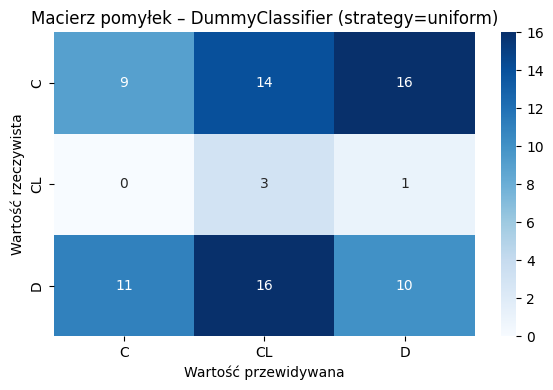

In [89]:
model = DummyClassifier(strategy="uniform", random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=model.classes_, yticklabels=model.classes_)
plt.title("Macierz pomyłek – DummyClassifier (strategy=uniform)")
plt.ylabel("Wartość rzeczywista")
plt.xlabel("Wartość przewidywana")
plt.tight_layout()
plt.show()

Jak widać dla bazowego modelu DummyClassifier, wszytskie parametry wypadają bardzo słabo, model częsciej błędnie klasyfikuje Status.


### Wnioski z analizy danych i wizualizacji:
Zdecydowana większość pacjentów to kobiety. Większy odsetek zgonów widać wśród mężczyzn. Nie da się jednoznacznie określić czy Stage choroby w jakim znajduje się pacjent ma wpływ na przeżycie. Obecność objawów klinicznych - Ascites, Hepatomegaly, Spiders oraz Edema zwiększa ryzyko śmierci, odsetek zgonów osób ze objawami klinicznymi jest wysoki, zwłaszcza dla cechy Ascites oraz Edema (ok. 80%). Podawany lek nie wykazuje znaczącej korelacji ze śmiertelnością pacjentów. Średnia wartość cechy Bilirubin jest wyższa dla pacjentów ze Statusem = 'D', natomiast Albumin pozostaje na podobnym poziomie dla wszystkich 3 Statusów.

# **Przetwarzanie danych i klasyfikacja**

Import potrzebnych elementów z biblioteki sklearn

In [90]:
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import precision_score, recall_score, f1_score

## Przygotowanie preprocessorów

Kolumny kategorialne zostały już zakodowane wcześniej (kodowanie binarne dla Sex/Ascites/Spiders oraz OHE dla Drug/Hepatomegaly/Edema). Dane przekazywane do modeli są w pełni numeryczne. Zdefiniowałam trzy warianty przetwarzania, które będę porównywać:
- **Baseline** – brak dodatkowego przetwarzania
- **Standaryzacja** – StandardScaler: sprowadzenie wszystkich kolumn numerycznych do tej samej skali (średniej=0 i odchylenia standardowego=1), tak aby model nie "myślał", że niektóre cechy są ważniejsze tylko dlatego, że mają większe liczby
- **PCA** – StandardScaler + redukcja wymiarowości przez PCA, która z 24 kolumn robi 10 "syntetycznych" cech, które zachowują jak najwięcej informacji. Wybrałam to przetwarzanie, ponieważ podczas ekploracji danych, można było zauważyć, że niektóre cechy są ze sobą powiązane

In [91]:
print(f'Liczba cech w X_train: {X_train.shape[1]} ')

def make_base_prep():
    return FunctionTransformer()

def make_std_prep():
    return StandardScaler()

def make_pca_pipe(model, n_components=10):
    return Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_components, random_state=42)),
        ('model', model),
    ])

Liczba cech w X_train: 24 


Funkcje pomocnicze to wyświetlania wyników

In [92]:
def compute_metrics(y_true, y_pred):
    return {
        'Accuracy':  accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall':    recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'F1':        f1_score(y_true, y_pred, average='weighted', zero_division=0),
    }

def plot_metrics_bar(df, x_col, title, figsize=(10, 5)):
    df_long = df.melt(id_vars=[x_col],
                      value_vars=['Accuracy', 'Precision', 'Recall', 'F1'],
                      var_name='Metryka', value_name='Wartosc')
    plt.figure(figsize=figsize)
    sns.barplot(data=df_long, x=x_col, y='Wartosc', hue='Metryka', palette='viridis')
    plt.title(title)
    plt.ylabel('Wartosc metryki')
    plt.ylim(0, 1)
    plt.xticks(rotation=20, ha='right')
    plt.legend(title='Metryka')
    plt.tight_layout()
    plt.show()

def plot_confusion(y_true, y_pred, title):
    classes = sorted(y_true.unique())
    cm = confusion_matrix(y_true, y_pred, labels=classes)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)
    plt.title(title)
    plt.ylabel('Rzeczywista')
    plt.xlabel('Przewidywana')
    plt.tight_layout()
    plt.show()

## Naiwny klasyfikator Bayesa (GaussianNB)

Naiwny klasyfikator Bayesa zaklada niezaleznosc cech i modeluje kazda ceche rozkladem normalnym. Klasyfikator uczy sie z danych treningowych rozkładu każdej cechy dola każdej klasy i na tej podstawie dla nowych danych oblicza na podstawie jej cech prawdopodobieństwo przynależności do każdej klasy i wybiera tę z największym. Model ten zakłada, że każda cecha ma rozkład normalny ( na wcześniejszych wykresach mogliśmy zaobserwować, że w rzeczywistości tak nie jest), dlatego kluczowym hiperparametrem dla klasyfikatora Bayesa jest var_smoothing, czyli inaczej wygładzenie wariancji. Ma ono zapobiegajać problemowi zerowej wariancji cech - jeżeli jakaś cecha ma w danych treningowych zawszę ta samą wartość, a w zbiorze testowym pojawi się pacjent z inna wartościa tej cechy to klasyfikator Bayesa przypisze prawdopodobieństwo =0 wystąpienia innej wartosci tej cechy, ponieważ wariancja tej cechy wynosi zero. Hiperparametr var_smoothing rowiązuje ten problem, dodając małą stałą do każej wariancji. To ten hiperparametr postawnowiłam dostroić.

### Baseline – bez przetwarzania danych

Naiwny klasyfikator Bayesa – Baseline
              precision    recall  f1-score   support

           C       0.77      0.77      0.77        39
          CL       0.33      0.50      0.40         4
           D       0.71      0.68      0.69        37

    accuracy                           0.71        80
   macro avg       0.61      0.65      0.62        80
weighted avg       0.72      0.71      0.72        80



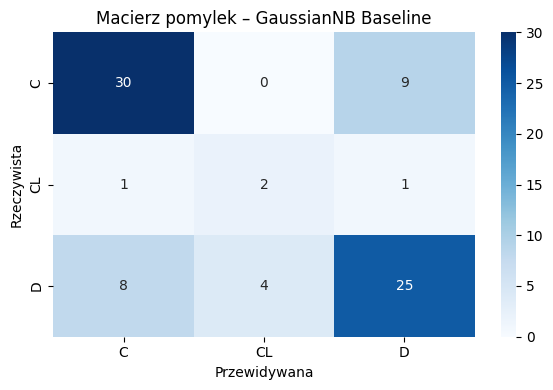

In [93]:
pipe_nb_base = Pipeline([
    ('prep', make_base_prep()),
    ('model', GaussianNB()),
])
pipe_nb_base.fit(X_train, y_train)
y_pred_nb_base = pipe_nb_base.predict(X_test)

print('Naiwny klasyfikator Bayesa – Baseline')
print(classification_report(y_test, y_pred_nb_base))
plot_confusion(y_test, y_pred_nb_base, 'Macierz pomylek – GaussianNB Baseline')

Jak widać wyniki są już dużo lepsze niż dla DummyClassifier. Accuracy = 71% co jest dobrym wynikiem startowym. Jednak zgodnie z wcześniejszymi przewidywaniami z ekploracji danych, model słabo przeiwduje status = CL z powodu małej liczby pacjentów z tym statusem. Precision i recall są równe odpwiednio 33 oraz 50%. Dla Statusu = 'D' oraz 'C' Recall oraz Precision są na podobnym poziomie i są zbliżone do accuracy. Z macierzy pomyłek możemy zobaczyć, że model najczęsciej odwrotnie klasyfikuje status 'D' z 'C i na odwrót.'

### Dostrojenie hiperparametru – var_smoothing

Testuje 6 wartosci `var_smoothing` (od 1e-9 do 0.1). Wieksza wartosc oznacza silniejsze wygładzenie.

var_smoothing  Accuracy  Precision  Recall       F1
        1e-09    0.7125   0.722024  0.7125 0.716181
        1e-07    0.7000   0.724932  0.7000 0.695092
        1e-05    0.6500   0.670386  0.6500 0.636812
        0.001    0.6375   0.668170  0.6375 0.617152
         0.01    0.6375   0.668481  0.6375 0.599797
          0.1    0.5625   0.604963  0.5625 0.497935


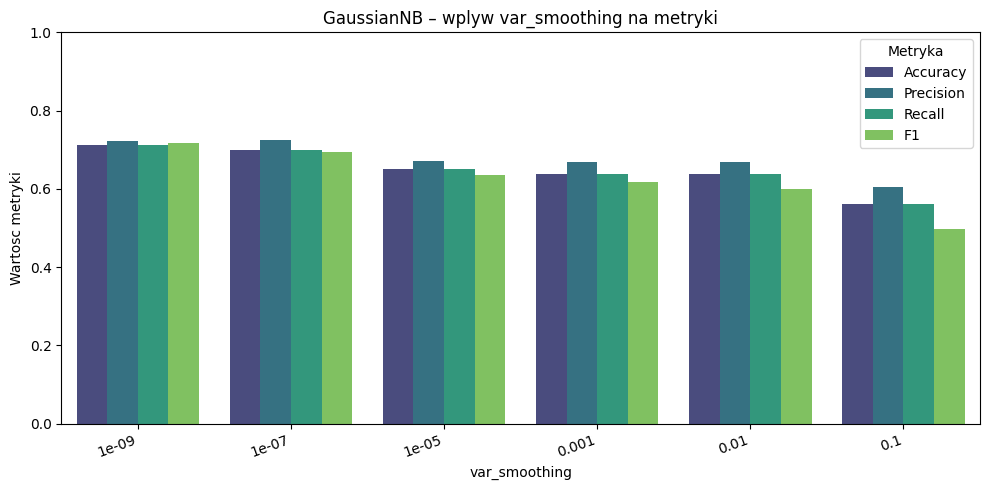

In [94]:
var_smoothing_values = [1e-9, 1e-7, 1e-5, 1e-3, 0.01, 0.1]
results_nb_hp = []

for vs in var_smoothing_values:
    pipe = Pipeline([
        ('prep', make_base_prep()),
        ('model', GaussianNB(var_smoothing=vs)),
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    m = compute_metrics(y_test, y_pred)
    m['var_smoothing'] = str(vs)
    results_nb_hp.append(m)

df_nb_hp = pd.DataFrame(results_nb_hp)
print(df_nb_hp[['var_smoothing', 'Accuracy', 'Precision', 'Recall', 'F1']].to_string(index=False))
plot_metrics_bar(df_nb_hp, 'var_smoothing', 'GaussianNB – wplyw var_smoothing na metryki')

Z wykresu oraz tabeli możemy zobaczyć, że zwiększanie hiperparametru var_smoothing powoduje obniżenie zarówno Acurracy jak i Recall oraz Precision. Niskie wygładzenie skutkuje najlepszymi wynikami. Może to oznaczać, iż nie ma u nas cech typowo jedno wartościowych, a zwiększanie prawdopodobieństwa wystąpienia danej wartości cechy powoduje to, że model jest mniej pewny siebie i częscięj sie myli.

### Wpływ przetwarzania danych na GaussianNB

Porównam wyniki dla najlepszego var_smoothing = 1e-09 przy trzech wariantach przetwarzania danych:
1. Baseline 
2. Standaryzacja (StandardScaler)
3. PCA (StandardScaler + PCA, n\_components=10)

Najlepsze var_smoothing: 1e-09
Przetwarzanie  Accuracy  Precision  Recall       F1
     Baseline    0.7125   0.722024  0.7125 0.716181
Standaryzacja    0.2375   0.473085  0.2375 0.274860
   PCA (n=10)    0.6750   0.664688  0.6750 0.664321


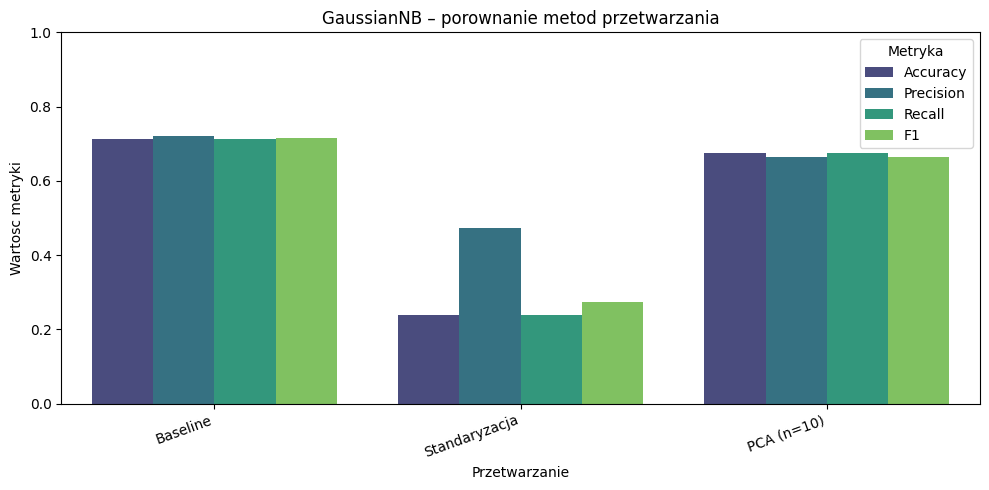

In [95]:
best_vs = float(df_nb_hp.loc[df_nb_hp['Accuracy'].idxmax(), 'var_smoothing'])
print(f'Najlepsze var_smoothing: {best_vs}')

prep_configs_nb = {
    'Baseline':      Pipeline([('prep', make_base_prep()), ('model', GaussianNB(var_smoothing=best_vs))]),
    'Standaryzacja': Pipeline([('prep', make_std_prep()),  ('model', GaussianNB(var_smoothing=best_vs))]),
    'PCA (n=10)':    make_pca_pipe(GaussianNB(var_smoothing=best_vs)),
}

results_nb_prep = []
for label, pipe in prep_configs_nb.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    m = compute_metrics(y_test, y_pred)
    m['Przetwarzanie'] = label
    results_nb_prep.append(m)

df_nb_prep = pd.DataFrame(results_nb_prep)
print(df_nb_prep[['Przetwarzanie', 'Accuracy', 'Precision', 'Recall', 'F1']].to_string(index=False))
plot_metrics_bar(df_nb_prep, 'Przetwarzanie', 'GaussianNB – porownanie metod przetwarzania')

*(Wniosek do uzupelnienia)*

## Drzewo decyzyjne (DecisionTreeClassifier)

Drzewo decyzyjne buduje hierarchie regul podzialu. Dostrajamy trzy hiperparametry:
- **max\_depth** – maksymalna glebokos drzewa (ogranicza przeuczenie)
- **criterion** – kryterium podzialu: `gini` lub `entropy`
- **min\_samples\_split** – minimalna liczba probek wymagana do podzialu wezla

### Baseline – bez przetwarzania danych

In [ ]:
pipe_dt_base = Pipeline([
    ('prep', make_base_prep()),
    ('model', DecisionTreeClassifier(random_state=42)),
])
pipe_dt_base.fit(X_train, y_train)
y_pred_dt_base = pipe_dt_base.predict(X_test)

print('=== Drzewo decyzyjne – Baseline ===')
print(classification_report(y_test, y_pred_dt_base))
plot_confusion(y_test, y_pred_dt_base, 'Macierz pomylek – DecisionTree Baseline')

*(Wniosek do uzupelnienia)*

### Dostrojenie hiperparametrow – siatka max\_depth × criterion × min\_samples\_split

Testujemy wszystkie kombinacje (4 × 2 × 3 = 24 konfiguracje). Wyniki wizualizujemy jako heatmapy Accuracy i F1 (uśrednione po min\_samples\_split) oraz barplot wplywu min\_samples\_split.

In [ ]:
max_depths = [3, 5, 10, None]
criteria   = ['gini', 'entropy']
min_splits = [2, 10, 20]
results_dt_hp = []

for depth in max_depths:
    for crit in criteria:
        for min_s in min_splits:
            pipe = Pipeline([
                ('prep', make_base_prep()),
                ('model', DecisionTreeClassifier(
                    max_depth=depth, criterion=crit,
                    min_samples_split=min_s, random_state=42
                )),
            ])
            pipe.fit(X_train, y_train)
            y_pred = pipe.predict(X_test)
            m = compute_metrics(y_test, y_pred)
            m['max_depth'] = str(depth)
            m['criterion'] = crit
            m['min_samples_split'] = min_s
            results_dt_hp.append(m)

df_dt_hp = pd.DataFrame(results_dt_hp)

for metric in ['Accuracy', 'F1']:
    pivot = df_dt_hp.groupby(['max_depth', 'criterion'])[metric].mean().unstack()
    plt.figure(figsize=(6, 4))
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis')
    plt.title(f'Drzewo decyzyjne – {metric} (sr. po min_samples_split)\nmax_depth × criterion')
    plt.tight_layout()
    plt.show()

df_min = df_dt_hp.groupby('min_samples_split')[['Accuracy','Precision','Recall','F1']].mean().reset_index()
df_min['min_samples_split'] = df_min['min_samples_split'].astype(str)
plot_metrics_bar(df_min, 'min_samples_split', 'Drzewo decyzyjne – wplyw min_samples_split (sr.)')

print('\nNajlepsza konfiguracja (wg Accuracy):')
print(df_dt_hp.loc[df_dt_hp['Accuracy'].idxmax(),
                   ['max_depth', 'criterion', 'min_samples_split', 'Accuracy', 'F1']])

*(Wniosek do uzupelnienia)*

### Wplyw przetwarzania danych na Drzewo decyzyjne

Porownujemy wyniki dla najlepszych hiperparametrow przy trzech wariantach przetwarzania.

In [ ]:
best_dt = df_dt_hp.loc[df_dt_hp['Accuracy'].idxmax()]
best_depth_dt = None if best_dt['max_depth'] == 'None' else int(best_dt['max_depth'])
best_crit_dt  = best_dt['criterion']
best_min_s_dt = int(best_dt['min_samples_split'])
print(f'Najlepsze params: max_depth={best_depth_dt}, criterion={best_crit_dt}, min_samples_split={best_min_s_dt}')

def make_best_dt():
    return DecisionTreeClassifier(
        max_depth=best_depth_dt, criterion=best_crit_dt,
        min_samples_split=best_min_s_dt, random_state=42
    )

prep_configs_dt = {
    'Baseline':      Pipeline([('prep', make_base_prep()), ('model', make_best_dt())]),
    'Standaryzacja': Pipeline([('prep', make_std_prep()),  ('model', make_best_dt())]),
    'PCA (n=10)':    make_pca_pipe(make_best_dt()),
}

results_dt_prep = []
for label, pipe in prep_configs_dt.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    m = compute_metrics(y_test, y_pred)
    m['Przetwarzanie'] = label
    results_dt_prep.append(m)

df_dt_prep = pd.DataFrame(results_dt_prep)
print(df_dt_prep[['Przetwarzanie', 'Accuracy', 'Precision', 'Recall', 'F1']].to_string(index=False))
plot_metrics_bar(df_dt_prep, 'Przetwarzanie', 'Drzewo decyzyjne – porownanie metod przetwarzania')

*(Wniosek do uzupelnienia)*

## Podsumowanie – porownanie wszystkich konfiguracji

In [ ]:
summary_rows = []
for row in results_nb_prep:
    summary_rows.append({**row, 'Model': 'GaussianNB'})
for row in results_dt_prep:
    summary_rows.append({**row, 'Model': 'DecisionTree'})

df_summary = pd.DataFrame(summary_rows)
df_summary['Konfiguracja'] = df_summary['Model'] + '\n' + df_summary['Przetwarzanie']

df_sum_long = df_summary.melt(
    id_vars='Konfiguracja',
    value_vars=['Accuracy', 'Precision', 'Recall', 'F1'],
    var_name='Metryka', value_name='Wartosc'
)

plt.figure(figsize=(14, 6))
sns.barplot(data=df_sum_long, x='Konfiguracja', y='Wartosc', hue='Metryka', palette='viridis')
plt.title('Porownanie wszystkich konfiguracji – GaussianNB vs Drzewo decyzyjne')
plt.ylabel('Wartosc metryki')
plt.ylim(0, 1)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

print(df_summary[['Model', 'Przetwarzanie', 'Accuracy', 'Precision', 'Recall', 'F1']].to_string(index=False))

*(Wniosek do uzupelnienia)*